In [2]:
import pandas as pd
import numpy as np

# Load the original dataset
df = pd.read_csv(
    "../data/raw/SeoulBikeData.csv",
    encoding="ISO-8859-1"
)

# Convert Date into datetime
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

# Create the hourly datetime index
df["DateTime"] = (
    df["Date"]
    + pd.to_timedelta(df["Hour"], unit="h")
)

# Sort and set index
ts_df = df.sort_values("DateTime").set_index("DateTime")

# Extract target time series
bike_series = ts_df["Rented Bike Count"].asfreq("h")

# Chronological split: 70% / 15% / 15%
train = bike_series.iloc[:6132]
validation = bike_series.iloc[6132:7446]
test = bike_series.iloc[7446:]

print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Validation period:", validation.index.min(), "to", validation.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

Training: 6132
Validation: 1314
Test: 1314

Training period: 2017-12-01 00:00:00 to 2018-08-13 11:00:00
Validation period: 2018-08-13 12:00:00 to 2018-10-07 05:00:00
Test period: 2018-10-07 06:00:00 to 2018-11-30 23:00:00


In [3]:
from statsmodels.tsa.statespace.structural import UnobservedComponents

# Build UCM with local linear trend and daily seasonality
ucm_model = UnobservedComponents(
    train,
    level="local linear trend",
    seasonal=24
)

# Fit the model
ucm_results = ucm_model.fit(disp=False)

# Display results
print(ucm_results.summary())

                            Unobserved Components Results                            
Dep. Variable:             Rented Bike Count   No. Observations:                 6132
Model:                    local linear trend   Log Likelihood              -40747.526
                   + stochastic seasonal(24)   AIC                          81503.053
Date:                       Tue, 17 Nov 2026   BIC                          81529.922
Time:                               18:03:12   HQIC                         81512.375
Sample:                           12-01-2017                                         
                                - 08-13-2018                                         
Covariance Type:                         opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sigma2.irregular  1.138e-06    280.270   4.06e-09      1

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Forecast the validation period
ucm_forecast = ucm_results.get_forecast(
    steps=len(validation)
)

ucm_predictions = ucm_forecast.predicted_mean

# Calculate evaluation metrics
ucm_mae = mean_absolute_error(
    validation,
    ucm_predictions
)

ucm_rmse = np.sqrt(
    mean_squared_error(validation, ucm_predictions)
)

print("UCM VALIDATION RESULTS")
print("----------------------")
print("MAE:", ucm_mae)
print("RMSE:", ucm_rmse)

UCM VALIDATION RESULTS
----------------------
MAE: 445.8194481659484
RMSE: 577.8963614328463


In [5]:
# UCM with local level and daily seasonality
ucm_simple_model = UnobservedComponents(
    train,
    level="local level",
    seasonal=24
)

# Fit the model
ucm_simple_results = ucm_simple_model.fit(disp=False)

# Display summary
print(ucm_simple_results.summary())

                            Unobserved Components Results                            
Dep. Variable:             Rented Bike Count   No. Observations:                 6132
Model:                           local level   Log Likelihood              -40752.087
                   + stochastic seasonal(24)   AIC                          81510.175
Date:                       Tue, 17 Nov 2026   BIC                          81530.327
Time:                               18:04:19   HQIC                         81517.167
Sample:                           12-01-2017                                         
                                - 08-13-2018                                         
Covariance Type:                         opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sigma2.irregular     0.0486    252.524      0.000      1

In [6]:
# Generate validation forecast
ucm_simple_forecast = ucm_simple_results.get_forecast(
    steps=len(validation)
)

ucm_simple_predictions = ucm_simple_forecast.predicted_mean

# Calculate metrics
ucm_simple_mae = mean_absolute_error(
    validation,
    ucm_simple_predictions
)

ucm_simple_rmse = np.sqrt(
    mean_squared_error(validation, ucm_simple_predictions)
)

print("SIMPLER UCM VALIDATION RESULTS")
print("------------------------------")
print("MAE:", ucm_simple_mae)
print("RMSE:", ucm_simple_rmse)

SIMPLER UCM VALIDATION RESULTS
------------------------------
MAE: 451.68189445558306
RMSE: 577.2330223442585


In [7]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Residuals from our selected UCM model
ucm_residuals = ucm_results.resid.dropna()

# Ljung-Box test at daily and weekly lags
ucm_ljungbox = acorr_ljungbox(
    ucm_residuals,
    lags=[24, 48, 168],
    return_df=True
)

print("UCM RESIDUAL DIAGNOSTICS")
print(ucm_ljungbox)

UCM RESIDUAL DIAGNOSTICS
         lb_stat  lb_pvalue
24   1705.997587        0.0
48   2255.490806        0.0
168  6155.331376        0.0


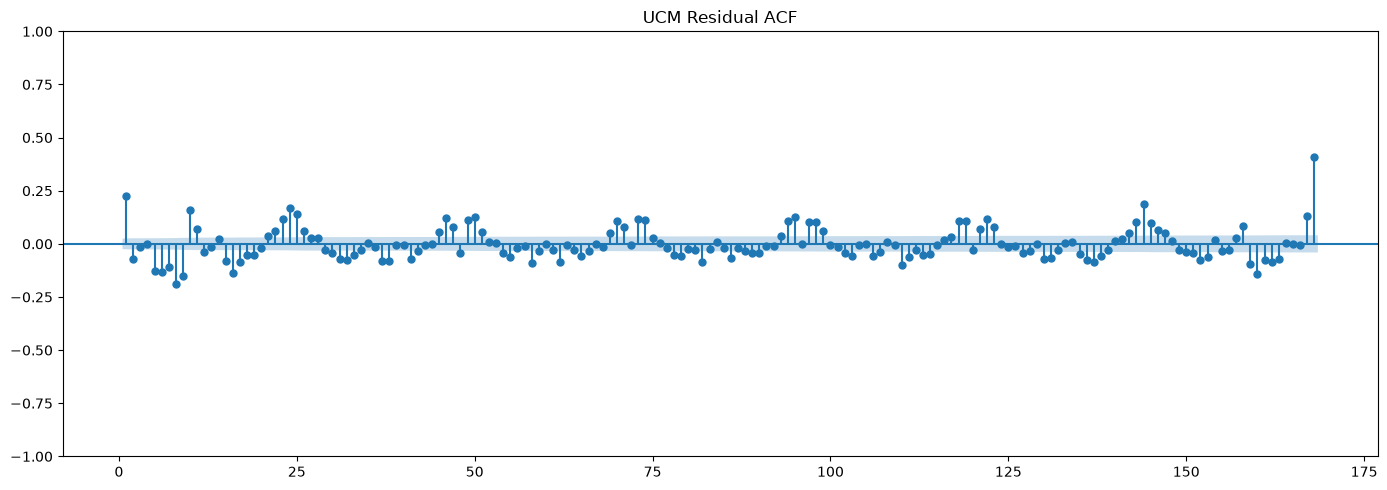

In [8]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    ucm_residuals,
    lags=168,
    zero=False,
    ax=ax
)

ax.set_title("UCM Residual ACF")
plt.tight_layout()

plt.savefig(
    "../results/figures/ucm_residual_acf.png",
    dpi=300
)

plt.show()